---
Vaibhav Kansal

---
1024160097

---

3P14

---

CC_A8

---

Q1

In [9]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

# Unique paragraph about technology (AI and Space exploration)
paragraph = "Artificial Intelligence is rapidly transforming our approach to space exploration. Autonomous rovers use advanced machine learning algorithms to navigate the rugged, unpredictable terrain of Mars without human intervention. Deep space probes rely on smart systems to analyze vast astronomical data streams and make real-time decisions. Meanwhile, satellite networks are using intelligent predictive models to monitor climate changes on Earth. This synergy between AI and space science is truly unlocking the secrets of the cosmos."

# 1. Convert text to lowercase and remove punctuation using re
cleaned_paragraph = paragraph.lower()
cleaned_paragraph = re.sub(r'[^\w\s]', '', cleaned_paragraph)

# 2. Tokenize the text into words and sentences
words_nltk = word_tokenize(cleaned_paragraph)
sentences = sent_tokenize(paragraph)
print("Sentences:", sentences)

# 3. Split using split() and word_tokenize()
words_split = cleaned_paragraph.split()
print("\n--- Comparison of split() and word_tokenize() ---")
print(f"Number of words with split(): {len(words_split)}")
print(f"Number of words with word_tokenize(): {len(words_nltk)}")
# Note: NLTK's word_tokenize splits contractions (e.g., "don't" -> "do", "n't") and handles punctuation more robustly than Python's basic whitespace split().

# 4. Remove stopwords (using NLTK's stopwords list)
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words_nltk if w not in stop_words]

# 5. Display word frequency distribution (excluding stopwords)
word_freq = Counter(filtered_words)
print("\nWord Frequency Distribution (excluding stopwords):")
for word, count in word_freq.most_common():
    print(f"{word}: {count}")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Sentences: ['Artificial Intelligence is rapidly transforming our approach to space exploration.', 'Autonomous rovers use advanced machine learning algorithms to navigate the rugged, unpredictable terrain of Mars without human intervention.', 'Deep space probes rely on smart systems to analyze vast astronomical data streams and make real-time decisions.', 'Meanwhile, satellite networks are using intelligent predictive models to monitor climate changes on Earth.', 'This synergy between AI and space science is truly unlocking the secrets of the cosmos.']

--- Comparison of split() and word_tokenize() ---
Number of words with split(): 74
Number of words with word_tokenize(): 74

Word Frequency Distribution (excluding stopwords):
space: 3
artificial: 1
intelligence: 1
rapidly: 1
transforming: 1
approach: 1
exploration: 1
autonomous: 1
rovers: 1
use: 1
advanced: 1
machine: 1
learning: 1
algorithms: 1
navigate: 1
rugged: 1
unpredictable: 1
terrain: 1
mars: 1
without: 1
human: 1
intervention: 

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Q2

In [4]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer

nltk.download('wordnet')

paragraph = "Artificial Intelligence is rapidly transforming our approach to space exploration. Autonomous rovers use advanced machine learning algorithms to navigate the rugged, unpredictable terrain of Mars without human intervention. Deep space probes rely on smart systems to analyze vast astronomical data streams and make real-time decisions. Meanwhile, satellite networks are using intelligent predictive models to monitor climate changes on Earth. This synergy between AI and space science is truly unlocking the secrets of the cosmos."

# 1. Extract all words with only alphabets using re.findall()
alphabetic_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())

# 2. Remove stop words using NLTK’s stopword list
stop_words = set(stopwords.words('english'))
filtered_alphabetic = [w for w in alphabetic_words if w not in stop_words]

# 3. Perform stemming with PorterStemmer
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_alphabetic]

# 4. Perform lemmatization with WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_alphabetic]

# 5. Compare and explain
print("Comparison:\nWord | Stemmed | Lemmatized")
print("-" * 35)
for orig, st, lem in zip(filtered_alphabetic[:15], stemmed_words[:15], lemmatized_words[:15]):
    print(f"{orig:<12} | {st:<10} | {lem:<10}")

# Explanation:
# Stemming relies on crude heuristic chopping of word endings (e.g. "rapidly" -> "rapidli"), whereas Lemmatization uses vocabulary and morphological analysis to return valid base words (e.g. "rapidly" -> "rapidly").
# Prefer Stemming when speed and efficiency are critical (e.g. search indexing). Prefer Lemmatization when grammatical accuracy and proper dictionary words are needed.

[nltk_data] Downloading package wordnet to /root/nltk_data...


Comparison:
Word | Stemmed | Lemmatized
-----------------------------------
artificial   | artifici   | artificial
intelligence | intellig   | intelligence
rapidly      | rapidli    | rapidly   
transforming | transform  | transforming
approach     | approach   | approach  
space        | space      | space     
exploration  | explor     | exploration
autonomous   | autonom    | autonomous
rovers       | rover      | rover     
use          | use        | use       
advanced     | advanc     | advanced  
machine      | machin     | machine   
learning     | learn      | learning  
algorithms   | algorithm  | algorithm 
navigate     | navig      | navigate  


Q3

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "Global stocks plunge as inflation concerns mount again.",
    "New smartphone features AI-powered camera and extended battery life.",
    "A delicious recipe for homemade chocolate chip cookies with organic ingredients."
]

# 1. CountVectorizer (Bag of Words)
cv = CountVectorizer(stop_words='english')
bow_matrix = cv.fit_transform(texts)
print("Bag of Words Vocabulary:", cv.get_feature_names_out())

# 2. TfidfVectorizer
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(texts)
feature_names = tfidf.get_feature_names_out()

# 3. Print and interpret top 3 keywords from each text
print("\nTop 3 keywords per text using TF-IDF:")
for i, text in enumerate(texts):
    scores = tfidf_matrix[i].toarray()[0]
    word_score_pairs = list(zip(feature_names, scores))
    sorted_pairs = sorted(word_score_pairs, key=lambda x: x[1], reverse=True)
    print(f"\nText {i+1}: '{text}'")
    print("Top keywords:", sorted_pairs[:3])

Bag of Words Vocabulary: ['ai' 'battery' 'camera' 'chip' 'chocolate' 'concerns' 'cookies'
 'delicious' 'extended' 'features' 'global' 'homemade' 'inflation'
 'ingredients' 'life' 'mount' 'new' 'organic' 'plunge' 'powered' 'recipe'
 'smartphone' 'stocks']

Top 3 keywords per text using TF-IDF:

Text 1: 'Global stocks plunge as inflation concerns mount again.'
Top keywords: [('concerns', np.float64(0.4082482904638631)), ('global', np.float64(0.4082482904638631)), ('inflation', np.float64(0.4082482904638631))]

Text 2: 'New smartphone features AI-powered camera and extended battery life.'
Top keywords: [('ai', np.float64(0.33333333333333337)), ('battery', np.float64(0.33333333333333337)), ('camera', np.float64(0.33333333333333337))]

Text 3: 'A delicious recipe for homemade chocolate chip cookies with organic ingredients.'
Top keywords: [('chip', np.float64(0.3535533905932738)), ('chocolate', np.float64(0.3535533905932738)), ('cookies', np.float64(0.3535533905932738))]


Q4

In [6]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

text_ai = """Artificial intelligence simulates human cognitive intelligence through algorithms.
It dynamically transforms modern automation, data analysis, and computer systems.
AI enables machine learning systems to adapt and evolve independently.
It powers neural networks capable of complex recognition and deep learning task execution."""

text_bc = """Blockchain technology represents a secure, decentralized digital ledger platform.
It establishes trust and cryptography without relying on central verification authorities.
Smart contracts execute predefined logical transactions securely across nodes automatically.
This system maintains immutable transaction blocks protecting records from manipulation."""

# 1. Preprocess and tokenize
def preprocess(text):
    words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
    return words

tokens_ai = preprocess(text_ai)
tokens_bc = preprocess(text_bc)

# 2. Calculate Similarity
# a. Jaccard Similarity
set_ai = set(tokens_ai)
set_bc = set(tokens_bc)
jaccard = len(set_ai.intersection(set_bc)) / len(set_ai.union(set_bc))

# b. Cosine Similarity
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_mat = vectorizer.fit_transform([text_ai, text_bc])
cosine_sim = cosine_similarity(tfidf_mat[0], tfidf_mat[1])[0][0]

print(f"Jaccard Similarity: {jaccard:.4f}")
print(f"Cosine Similarity: {cosine_sim:.4f}")

# c. Analysis:
# Cosine similarity using TF-IDF is often better because it accounts for term frequency and down-weights common words. Jaccard similarity is purely based on set membership and ignores frequency.

Jaccard Similarity: 0.0274
Cosine Similarity: 0.0000


Q5

Review 1: 'This wireless mechanical keyboard is absolutely amazing! The tactile feedback is highly satisfying, and the battery life lasts for weeks.'
  Polarity: 0.62, Subjectivity: 0.95 -> Positive

Review 2: 'The keys started sticking within two days, and the build quality is extremely cheap and disappointing.'
  Polarity: -0.10, Subjectivity: 0.70 -> Neutral

Review 3: 'It is a decent keyboard for the price, neither outstanding nor terrible. Quite average.'
  Polarity: -0.12, Subjectivity: 0.74 -> Negative



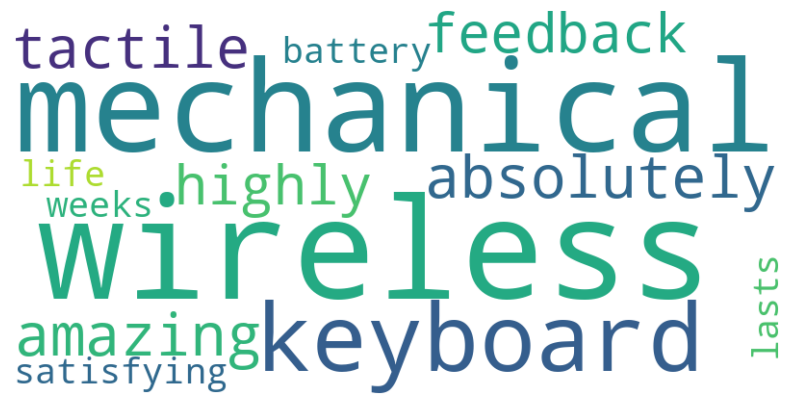

In [7]:
!pip install wordcloud

import matplotlib.pyplot as plt
from wordcloud import WordCloud
from textblob import TextBlob

# Short review for a product
reviews = [
    "This wireless mechanical keyboard is absolutely amazing! The tactile feedback is highly satisfying, and the battery life lasts for weeks.",
    "The keys started sticking within two days, and the build quality is extremely cheap and disappointing.",
    "It is a decent keyboard for the price, neither outstanding nor terrible. Quite average."
]

pos_text = ""

for i, r in enumerate(reviews):
    blob = TextBlob(r)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0.1:
        sentiment = "Positive"
        pos_text += " " + r
    elif polarity < -0.1:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"Review {i+1}: '{r}'\n  Polarity: {polarity:.2f}, Subjectivity: {subjectivity:.2f} -> {sentiment}\n")

# 3. Create a word cloud for all positive reviews
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(pos_text)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

Q6

In [8]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Training paragraph (~100 words)
training_text = """Artificial intelligence is changing the world very rapidly today.
Machine learning systems learn from data to make smart predictions and choices.
Neural networks mimic human brain structures to solve highly complex tasks.
Deep learning model structures process vast datasets to recognize images and generate text.
Every industry is adopting automation to speed up operations and improve accuracy.
Data science techniques help discover hidden patterns and construct reliable predictions.
AI technology advances rapidly to assist humans in scientific discovery and software development."""

# 1. Tokenize text using Tokenizer()
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1

# 2. Create input sequences
input_sequences = []
for line in training_text.split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X, y = input_sequences[:,:-1], input_sequences[:,-1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

# Build simple LSTM model
model = Sequential([
    Embedding(total_words, 16, input_length=max_sequence_len-1),
    LSTM(50),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, y, epochs=150, verbose=0)  # trained silently for demonstration

# 3. Generate 2-3 lines of text starting from a seed word
def generate_text(seed_text, next_words):
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([seed_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len-1, padding='pre')
        predicted = np.argmax(model.predict(token_list, verbose=0), axis=-1)

        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted:
                output_word = word
                break
        seed_text += " " + output_word
    return seed_text

print("Generated text:")
print(generate_text("artificial", 15))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Generated text:
artificial learning learning learning structures structures to to images and and choices text text development development
